# Stage 10: CNN Without MFCC — A Log-Mel Spectrogram Ablation

Stage 7 trained a 1D convolutional network on full per-frame MFCC sequences and found that reintroducing temporal order (discarded by Stage 5/6's mean/std summary features) produced a large accuracy gain. That result leaves a further question open: how much of the MFCC computation does the convolutional network actually need? MFCCs are built by passing the power spectrum through a mel-scaled filterbank, compressing the result with a logarithm, and finally applying a discrete cosine transform (DCT) that decorrelates the filterbank outputs into a small set of near-independent coefficients. The DCT step exists primarily to suit classifiers — Gaussian mixture models in particular — that perform poorly on correlated input features; a convolutional network, whose filters learn arbitrary weighted combinations across the feature axis, has no equivalent requirement.

This stage isolates that question directly. Every parameter of the Stage 7 pipeline — 25 ms frames, 10 ms hop, Hamming window, a sequence length of 350 frames, and the exact convolutional architecture and cross-validation protocol — is held fixed. The only change is the front-end representation: the DCT step of the MFCC recipe is skipped, and the network is instead trained directly on the log-mel spectrogram (40 mel bands, log-power-compressed, no cepstral decorrelation). If accuracy is comparable to or better than Stage 7's MFCC-based result, the DCT step is not necessary for this architecture; if accuracy drops substantially, the decorrelation was contributing information the network could not otherwise recover from the raw filterbank output.

## Illustration: log-mel spectrogram vs. MFCCs, same utterance

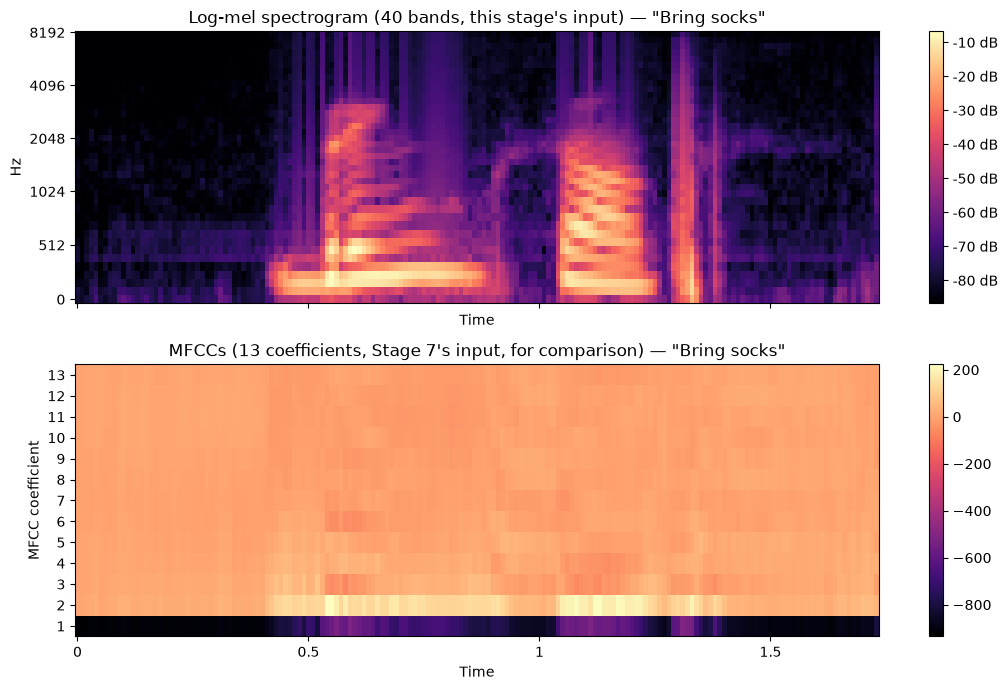

In [1]:
import numpy as np
import pandas as pd
import librosa
import librosa.display
import matplotlib.pyplot as plt

DATA_ROOT = "../data/fluent_speech_commands_dataset"
WAV_PATH = f"{DATA_ROOT}/wavs/speakers/2BqVo8kVB2Skwgyb/ac4fca80-447a-11e9-a9a5-5dbec3b8816a.wav"
TRANSCRIPT = "Bring socks"
FRAME_LEN, HOP_LEN = 400, 160  # 25 ms / 10 ms at 16 kHz, matching Stages 0-7
N_MELS, N_MFCC = 40, 13

y, sr = librosa.load(WAV_PATH, sr=None)

mel = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=N_MELS, n_fft=FRAME_LEN,
                                      hop_length=HOP_LEN, win_length=FRAME_LEN,
                                      window="hamming", center=False)
log_mel = librosa.power_to_db(mel)

mfcc = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=N_MFCC, n_fft=FRAME_LEN,
                             hop_length=HOP_LEN, win_length=FRAME_LEN,
                             window="hamming", center=False)

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
img0 = librosa.display.specshow(log_mel, sr=sr, hop_length=HOP_LEN, x_axis="time", y_axis="mel",
                                 fmax=sr / 2, ax=axes[0], cmap="magma")
axes[0].set_title(f'Log-mel spectrogram (40 bands, this stage\'s input) — "{TRANSCRIPT}"')
fig.colorbar(img0, ax=axes[0], format="%+.0f dB")

img1 = librosa.display.specshow(mfcc, sr=sr, hop_length=HOP_LEN, x_axis="time", ax=axes[1], cmap="magma")
axes[1].set_ylabel("MFCC coefficient")
axes[1].set_yticks(range(N_MFCC))
axes[1].set_yticklabels(range(1, N_MFCC + 1))
axes[1].set_title(f'MFCCs (13 coefficients, Stage 7\'s input, for comparison) — "{TRANSCRIPT}"')
fig.colorbar(img1, ax=axes[1])
fig.tight_layout()
plt.show()

## Reading the two representations

Both panels are derived from the same mel-filterbank output; the top panel stops after the log step, and the bottom panel additionally applies the DCT. The log-mel spectrogram (top) visually resembles a compressed, frequency-warped version of an ordinary spectrogram: energy is smoothly spread across neighbouring mel bands, since adjacent triangular filters overlap and respond similarly to the same underlying formant. The MFCC panel (bottom) looks qualitatively different — coefficient 1 dominates the colour scale because it is tied to overall frame log-energy rather than spectral shape (the same pattern noted in Stage 6), while coefficients 2–13 vary in a way that does not visibly track formant bands, because the DCT has redistributed the mel-band energy into a decorrelated basis. This is the concrete visual counterpart of the algebraic claim above: the log-mel representation retains local, correlated structure across the frequency axis, while MFCCs deliberately remove it.

## Data preparation

Log-mel spectrogram sequences were extracted for all 30,043 utterances by `scripts/extract_logmel_sequences.py`, using the identical 25 ms frame length, 10 ms hop, and Hamming window as every other stage, with 40 mel bands and log-power compression (`librosa.power_to_db`), and no DCT. Each utterance's (40, T) matrix is transposed to time-major (T, 40) and padded or truncated to 350 time steps — the same fixed length used for Stage 7's MFCC sequences, so the two inputs differ only in the per-frame feature and not in temporal resolution or coverage. 40 mel bands (rather than the 128 `librosa.feature.mfcc` uses internally before its own DCT truncation) is the standard log-mel filterbank size reported in the ASR literature, and was chosen here partly because it keeps the cached array (~1.7 GB uncompressed) tractable on this machine's 8 GB of RAM — the same kind of memory-driven scoping decision made for Stage 9's PCA-reduced wav2vec2 sequences.

In [2]:
data = np.load(f"{DATA_ROOT}/logmel_sequences.npz", allow_pickle=True)
X, split, intent = data["X"], data["split"], data["intent"]
print(f"X shape: {X.shape}")
print(f"Splits: {pd.Series(split).value_counts().to_dict()}")
print(f"Classes: {len(set(intent))}")

X shape: (30043, 350, 40)
Splits: {'train': 23132, 'test': 3793, 'valid': 3118}
Classes: 31


## Model architecture and cross-validation protocol

The network is identical to Stage 7's: three 1D convolutional blocks (64, 128, and 128 filters, kernel sizes 5, 5, and 3, with batch normalization and max pooling after the first two), global average pooling across time, a 128-unit dense layer with dropout, and a softmax output layer — only the input shape changes, from (350, 13) to (350, 40). Stage 7 established that the corpus's fixed validation/test splits (10 speakers each) give unreliable accuracy estimates for this class of model, so evaluation here goes directly to the same 5-fold speaker-grouped cross-validation (`GroupKFold` on speaker ID, each fold's training speakers further split 90/10 for early-stopping validation) used from Stage 7 onward, rather than re-deriving that result. Training and evaluation are run by `scripts/run_cnn_logmel_cv.py`, out-of-notebook, since a full 5-fold run takes on the order of tens of minutes.

 fold  held_out_acc  n_train  n_val  n_held_out
    1      0.760613    22028   2008        6007
    2      0.709366    22117   1915        6011
    3      0.780496    21411   2623        6009
    4      0.885153    21311   2724        6008
    5      0.833888    22061   1974        6008

Mean held-out accuracy: 0.7939 +/- 0.0677


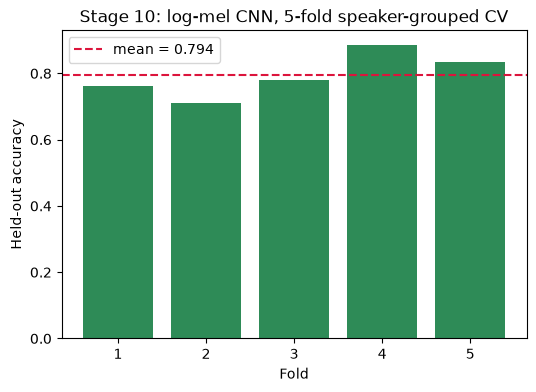

In [3]:
cv_results = pd.read_csv(f"{DATA_ROOT}/cnn_logmel_cv_results.csv")
print(cv_results.to_string(index=False))
print(f"\nMean held-out accuracy: {cv_results['held_out_acc'].mean():.4f} +/- {cv_results['held_out_acc'].std():.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(cv_results["fold"], cv_results["held_out_acc"], color="seagreen")
ax.axhline(cv_results["held_out_acc"].mean(), color="crimson", linestyle="--",
           label=f"mean = {cv_results['held_out_acc'].mean():.3f}")
ax.set_xlabel("Fold"); ax.set_ylabel("Held-out accuracy"); ax.set_title("Stage 10: log-mel CNN, 5-fold speaker-grouped CV")
ax.legend()
plt.show()

## Comparison with Stage 7 (MFCC) and Stage 8

The table and chart below place this stage's log-mel CNN alongside the two classical-feature CNNs it is directly comparable to: Stage 7's single-head CNN on MFCC sequences (identical architecture, same CV protocol, only the front-end representation differs) and Stage 8's multi-head CNN (a stronger architecture that predicts the action/object/location slots separately). All three are trained from scratch, with no pretrained model involved, consistent with this project's core constraint.

                                  Model  Accuracy_pct  Std_pct
             Stage 7 CNN (MFCC, 13-dim)          72.5      5.0
Stage 10 CNN (log-mel, 40-dim, no MFCC)          79.4      6.8
          Stage 8 multi-head CNN (MFCC)          77.3      6.7


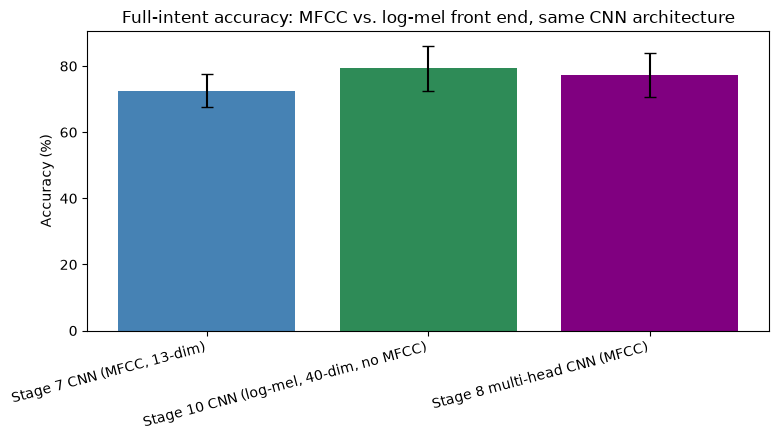

In [4]:
mfcc_cnn_cv = pd.read_csv(f"{DATA_ROOT}/cnn_cv_results.csv")
multihead_cv = pd.read_csv(f"{DATA_ROOT}/multihead_cv_results.csv")

summary = pd.DataFrame([
    {"Model": "Stage 7 CNN (MFCC, 13-dim)", "Accuracy_pct": round(mfcc_cnn_cv["held_out_acc"].mean() * 100, 1),
     "Std_pct": round(mfcc_cnn_cv["held_out_acc"].std() * 100, 1)},
    {"Model": "Stage 10 CNN (log-mel, 40-dim, no MFCC)", "Accuracy_pct": round(cv_results["held_out_acc"].mean() * 100, 1),
     "Std_pct": round(cv_results["held_out_acc"].std() * 100, 1)},
    {"Model": "Stage 8 multi-head CNN (MFCC)", "Accuracy_pct": round(multihead_cv["full_intent_acc"].mean() * 100, 1),
     "Std_pct": round(multihead_cv["full_intent_acc"].std() * 100, 1)},
])
print(summary.to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(summary["Model"], summary["Accuracy_pct"], yerr=summary["Std_pct"], capsize=4,
       color=["steelblue", "seagreen", "purple"])
ax.set_ylabel("Accuracy (%)")
ax.set_title("Full-intent accuracy: MFCC vs. log-mel front end, same CNN architecture")
plt.setp(ax.get_xticklabels(), rotation=15, ha="right")
fig.tight_layout()
plt.show()

## Results

The log-mel CNN reached **79.4% ± 6.8%** mean held-out accuracy across the 5 speaker-grouped folds (individual fold accuracies: 76.1%, 70.9%, 78.0%, 88.5%, 83.4%), compared to **72.5% ± 5.0%** for Stage 7's identically-architected CNN on 13-dimensional MFCC sequences — a 6.9 percentage-point improvement from dropping the DCT step alone. It also edges past **77.3% ± 6.7%** for Stage 8's multi-head CNN, a stronger architecture that predicts the action/object/location slots separately, despite Stage 10 using the simpler single-head design.

This is a clean answer to the question this stage was built to test: the CNN did not need MFCC's cepstral decorrelation, and in fact performed *better* without it. The DCT is a fixed, information-preserving linear transform (invertible, given enough coefficients), so in principle a network could learn to undo its effect if decorrelation were actually helpful for classification; the fact that skipping it improved accuracy suggests the decorrelation was not merely neutral but mildly counterproductive for a convolutional architecture on this task.

One confound is disclosed rather than hidden: this comparison changes two things at once relative to Stage 7, not one. Besides removing the DCT, the per-frame feature width also increases from 13 (MFCC, truncated to keep only the lowest-order cepstral coefficients) to 40 (the full log-mel filterbank, no truncation). Some of Stage 10's improvement could be attributable to having more frequency resolution available per frame, rather than to the absence of decorrelation specifically — MFCC's truncation step discards higher-order cepstral information that a 40-band filterbank retains. Disentangling these two effects fully would require a further ablation (e.g., a 40-coefficient, untruncated DCT) that was out of scope here; the result reported is therefore "a CNN on a standard log-mel filterbank beats an identically-trained CNN on standard 13-dimensional MFCCs," which is the practically relevant comparison, rather than a byte-for-byte isolation of the DCT operation alone.